# Notebook 04: Agglomerative Hierarchical Clustering (CAH)

**Purpose.** Apply hierarchical clustering to the same features and users as K-Means, so the two methods can be compared fairly.

## A. What is hierarchical clustering?

**Agglomerative** means bottom-up:

1. Start with every user as a cluster of one.
2. Merge the two closest clusters.
3. Repeat until everything is one cluster.

The result is not a single partition but a full **tree of merges**, called a dendrogram. Cutting the tree at a chosen height gives a partition.

**Reading a dendrogram:** the vertical position of a join shows how far apart two clusters were when they merged. A long vertical stretch before the next merge suggests well-separated groups, and cutting across such a stretch is a natural choice.

**Linkage methods** define the distance between two clusters:

| Linkage | Distance between clusters | Typical behaviour |
|---|---|---|
| **Ward** | Increase in within-cluster variance caused by merging | Compact clusters of similar size; requires Euclidean distance |
| **Average** | Average distance across all pairs of members | Sensitive to outliers; can produce one giant cluster |
| **Complete** | Distance between the two farthest members | Compact clusters; sensitive to outliers |
| **Single** | Distance between the two closest members | Chains through continuous clouds; can leave one giant cluster |

We use Euclidean distance on the same standardized features as K-Means.

**K-Means versus CAH:**

| | K-Means | CAH |
|---|---|---|
| Decisions | Revisable: users can change cluster at every step | Final: a merge is never undone |
| `k` | Chosen before fitting | Chosen after fitting by cutting the tree |
| Randomness | Depends on starting points | Deterministic, for a given order of the data |
| New users | Can be assigned to the nearest centroid | No built-in way to assign new users |

In [1]:
import sys
sys.path.append("..")

import json
import time

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

from src.clustering import (
    assign_to_nearest_centroid,
    cut_height,
    cut_tree,
    full_ward_linkage,
    name_segments,
    permute_columns,
    sample_linkage,
)
from src.data_loader import ensure_output_dirs, load_clean_data, load_config, load_representation, project_path
from src.evaluation import (
    compare_to_reference,
    internal_metrics,
    make_evaluation_index,
    reference_scan,
    scan_hierarchy,
    size_table,
    stability_table,
    summarise_reference,
)
from src.visualization import (
    apply_plot_style,
    plot_linkage_dendrograms,
    plot_linkage_metrics,
    plot_merge_heights,
    plot_metrics_vs_reference,
    plot_pca_segments,
    plot_single_dendrogram,
    plot_stability,
    save_figure,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

config = load_config()
ensure_output_dirs(config)
apply_plot_style()

METRICS_DIR = project_path(config["paths"]["metrics_dir"])
PROFILES_DIR = project_path(config["paths"]["profiles_dir"])
SEED = config["random_seed"]
EVALUATION = config["evaluation"]
K_VALUES = list(range(EVALUATION["k_min"], EVALUATION["k_max"] + 1))
NUMERIC_FEATURES = config["columns"]["representation_a_numeric"]

users = load_clean_data(config)
representation_a = load_representation(config, "a")
representation_b = load_representation(config, "b")
assert (representation_a.index == users["user_id"]).all(), "Features and users must be in the same order"
assert (representation_b.index == users["user_id"]).all(), "Features and users must be in the same order"

X = representation_a.to_numpy()
X_mixed = representation_b.to_numpy()

# The same users are used to compute Silhouette for every candidate of both algorithms.
silhouette_index = make_evaluation_index(len(X), EVALUATION["silhouette_sample_size"], SEED)
print("Representation A:", X.shape, "| Representation B:", X_mixed.shape)

Representation A: (50000, 4) | Representation B: (50000, 21)


## B. Computational considerations

The textbook algorithm stores the distance between every pair of users: `n(n-1)/2` values at 8 bytes each. The next cell works out what that means, then times real runs.

In [2]:
def distance_matrix_gigabytes(n_users):
    return n_users * (n_users - 1) / 2 * 8 / 1e9

feasibility = pd.DataFrame({"users": [1000, 5000, 10000, 20000, 50000]})
feasibility["pairwise_distances"] = feasibility["users"] * (feasibility["users"] - 1) // 2
feasibility["distance_matrix_GB"] = feasibility["users"].map(distance_matrix_gigabytes).round(3)

rng = np.random.default_rng(SEED)
scipy_seconds, vector_seconds = [], []
for size in feasibility["users"]:
    subset = X[rng.choice(len(X), size=int(size), replace=False)]
    if size <= 10000:
        start = time.perf_counter()
        sample_linkage(subset, "ward")
        scipy_seconds.append(round(time.perf_counter() - start, 2))
    else:
        scipy_seconds.append(np.nan)
    start = time.perf_counter()
    full_ward_linkage(subset)
    vector_seconds.append(round(time.perf_counter() - start, 2))

feasibility["scipy_ward_seconds"] = scipy_seconds
feasibility["fastcluster_vector_ward_seconds"] = vector_seconds
feasibility.to_csv(METRICS_DIR / "cah_feasibility.csv", index=False)
feasibility

,users,pairwise_distances,distance_matrix_GB,scipy_ward_seconds,fastcluster_vector_ward_seconds
0,1000,499500,0.004,0.01,0.00
1,5000,12497500,0.100,0.26,0.05
2,10000,49995000,0.400,1.05,0.20
3,20000,199990000,1.600,NaN,0.78
4,50000,1249975000,10.000,NaN,4.87


**Result.** The distance matrix for all users would need **10 GB** before any clustering work begins. The machine used here has 14 GB in total and had about 5 GB free when the project was built, so the standard approach is not feasible for the full data. SciPy runs were limited to 10,000 users to stay well within memory.

The bottleneck is **memory rather than time**. `fastcluster`'s vector-based Ward completed all 50,000 users in about 5 seconds, using no distance matrix. This is the one dependency added beyond the standard list, because it is what allows a true hierarchical solution for all users. It makes the comparison with K-Means fair without any extrapolation.

## C. Sampling strategy for dendrograms and linkage comparison

Average and complete linkage need the full distance matrix, and a dendrogram with 50,000 leaves would be unreadable anyway. So we compare linkages on a **uniform random sample of 5,000 users** with a fixed seed.

**Caveat:** results from a sample describe that sample. They do not prove what would happen on the complete dataset, so this sample is used only to choose the linkage and to illustrate the tree. We first check that it resembles the full data.

In [3]:
cah_settings = config["hierarchical"]
SELECTED_K = cah_settings["selected_k"]

sample_index = np.random.default_rng(SEED).choice(len(X), size=cah_settings["sample_size"], replace=False)
X_sample = X[sample_index]

representativeness = pd.DataFrame(
    {
        "all_users_mean": users[NUMERIC_FEATURES].mean(),
        "sample_mean": users.iloc[sample_index][NUMERIC_FEATURES].mean(),
        "all_users_std": users[NUMERIC_FEATURES].std(),
        "sample_std": users.iloc[sample_index][NUMERIC_FEATURES].std(),
    }
).round(3)
representativeness

,all_users_mean,sample_mean,all_users_std,sample_std
avg_listening_hours_per_week,9.989,10.023,3.969,3.985
playlists_created,8.003,8.018,2.832,2.792
avg_skips_per_day,10.026,10.037,3.166,3.174
music_suggestion_rating_1_to_5,3.644,3.639,1.114,1.114


## D. Comparing linkage methods on the sample

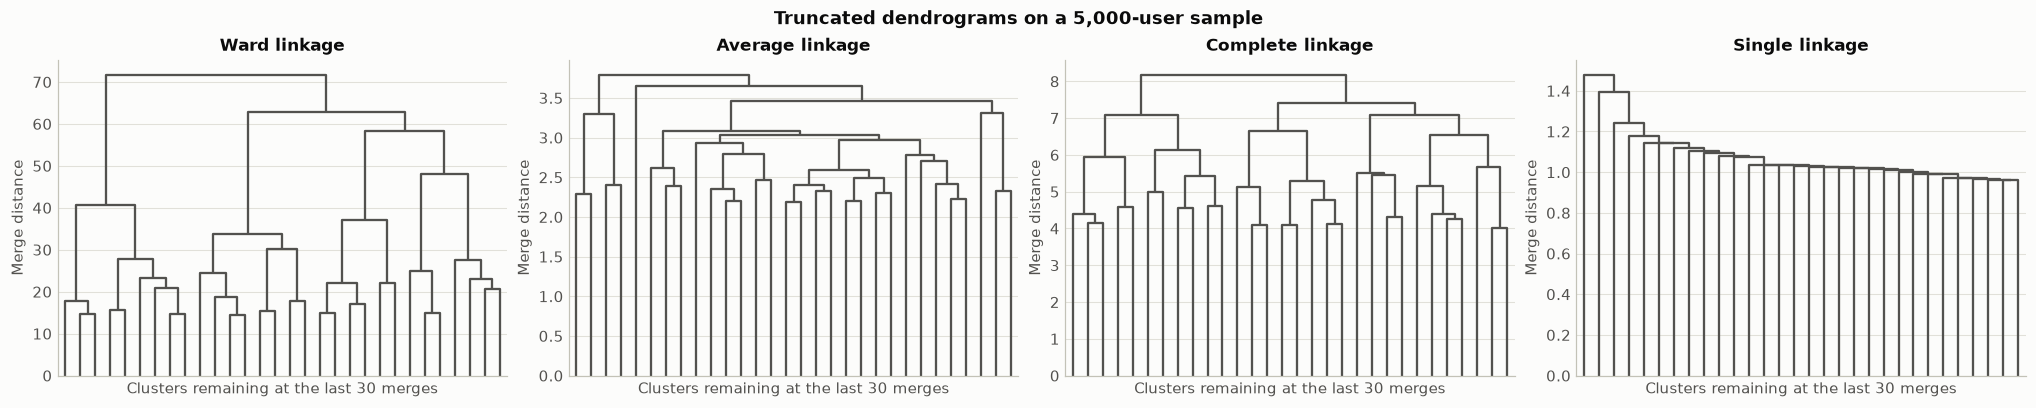

In [4]:
sample_linkages = {method: sample_linkage(X_sample, method) for method in cah_settings["linkage_methods"]}

fig = plot_linkage_dendrograms(sample_linkages, f"Truncated dendrograms on a {cah_settings['sample_size']:,}-user sample")
save_figure(fig, "cah_linkage_dendrograms", config)

silhouette                        smallest_cluster_share                        largest_cluster_share                       
linkage    average complete single   ward                average complete single   ward               average complete single   ward
k                                                                                                                                   
2            0.279    0.101  0.419  0.151                  0.003    0.483    0.0  0.237                 0.997    0.517  1.000  0.763
3            0.166    0.084  0.345  0.121                  0.003    0.221    0.0  0.230                 0.990    0.483  1.000  0.533
4            0.078    0.071  0.301  0.114                  0.003    0.139    0.0  0.218                 0.987    0.483  0.999  0.315
5            0.014    0.076  0.268  0.098                  0.001    0.139    0.0  0.137                 0.987    0.329  0.999  0.237
6           -0.009    0.075  0.175  0.097                  0.001    0.085    0.0  0.068                 0.987    0.329  0.999  0.230
7           -0.016    0.075  0.155  0.090                  0.001    0.064    0.0  0.068                 0.910    0.329  0.999  0.230
8           -0.027    0.083  0.142  0.096                  0.001    0.064    0.0  0.068                 0.849    0.174  0.999  0.178
9            0.018    0.075  0.107  0.089                  0.001    0.049    0.0  0.049                 0.699    0.174  0.998  0.178
10          -0.000    0.069  0.100  0.087                  0.001    0.018    0.0  0.049                 0.699    0.174  0.998  0.178

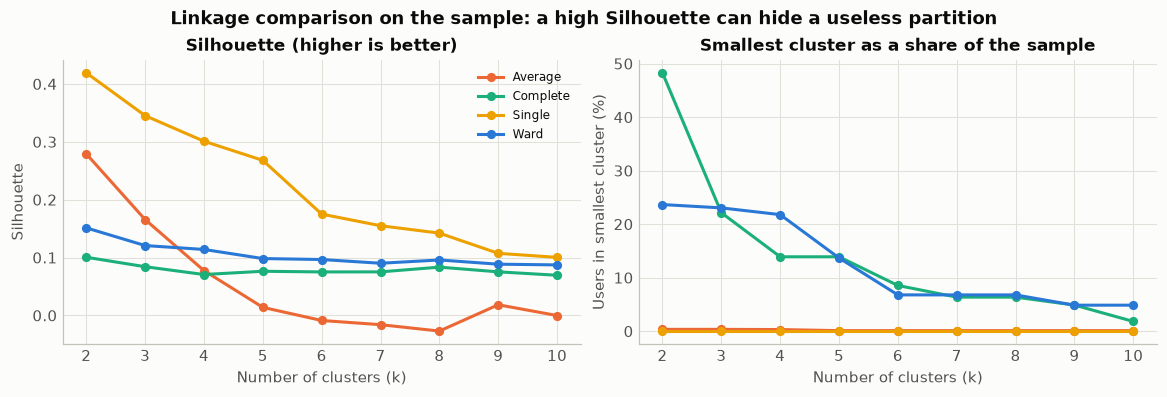

In [5]:
linkage_scans = pd.concat(
    [scan_hierarchy(X_sample, matrix, K_VALUES).assign(linkage=method) for method, matrix in sample_linkages.items()],
    ignore_index=True,
)
linkage_scans.to_csv(METRICS_DIR / "cah_linkage_comparison_sample.csv", index=False)

fig = plot_linkage_metrics(linkage_scans, "Linkage comparison on the sample: a high Silhouette can hide a useless partition")
save_figure(fig, "cah_linkage_metrics", config)

linkage_scans.pivot(index="k", columns="linkage", values=["silhouette", "smallest_cluster_share", "largest_cluster_share"]).round(3)

**Result: Ward is selected.**

- **Single linkage has the highest Silhouette of all (0.419 at `k = 2`, and 0.268 at `k = 5`), and it is useless:** at `k = 5`, one cluster holds 4,996 of the 5,000 sampled users and the other four clusters hold one user each. Davies-Bouldin rewards it as well (0.478), and only Calinski-Harabasz (about 4) exposes the problem. Single linkage chains through a continuous cloud and peels off isolated points. This is a clear example of why a metric cannot be used without looking at cluster sizes.
- **Average linkage fails in a similar way:** its Silhouette is 0.279 at `k = 2`, with one cluster holding 99.7% of the sample. It stays dominated by one giant cluster until `k = 7` (91.0%).
- **Complete linkage** gives more balanced clusters at low `k`, but its Silhouette is below Ward's at every `k`.
- **Ward** gives balanced clusters and the best Silhouette among the usable options. It also has a vector-based algorithm, which makes the full dataset feasible. Single linkage has one too, so feasibility alone does not separate those two; the useless partition does.

**A consequence to keep in mind:** Ward and K-Means both aim to minimize within-cluster variance, so they are related methods. Any agreement between them is not fully independent confirmation.

**Sample limitation:** this comparison uses a 5,000-user sample and does not prove what the other linkages would do on all users.

### Do the implementations agree?

We are about to use `fastcluster` for the full dataset, so we check on the sample that it matches SciPy and scikit-learn's `AgglomerativeClustering`, the implementation most students know. ARI of 1 means identical partitions.

In [6]:
scipy_labels = cut_tree(sample_linkages["ward"], SELECTED_K)
fastcluster_labels = cut_tree(full_ward_linkage(X_sample), SELECTED_K)
sklearn_labels = AgglomerativeClustering(n_clusters=SELECTED_K, linkage="ward").fit_predict(X_sample)

implementation_agreement = {
    "fastcluster vs SciPy": adjusted_rand_score(scipy_labels, fastcluster_labels),
    "scikit-learn vs SciPy": adjusted_rand_score(scipy_labels, sklearn_labels),
}
print({name: round(score, 4) for name, score in implementation_agreement.items()})

{'fastcluster vs SciPy': 1.0, 'scikit-learn vs SciPy': 1.0}


**Result.** All three implementations give identical partitions on the sample (ARI = 1.0), so using `fastcluster` does not change the method. It only makes it more efficient.

## E. Fitting Ward on all 50,000 users

Vector-based Ward works directly from feature vectors, so it needs no distance matrix. This gives **real hierarchical clusters for every user**, with no need to extrapolate from a sample and no shortcut assignment step. `scikit-learn`'s `AgglomerativeClustering` also has no `predict` method, so extending a sample-based model to the other 45,000 users would have required a separate rule.

Ward linkage on 50,000 users: 5.0 seconds


,0,1,2,3,4,5,6,7,8,9
k_before_merge,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0
merge_distance,219.9,194.4,177.7,170.3,124.6,110.3,96.1,95.0,90.0,85.2


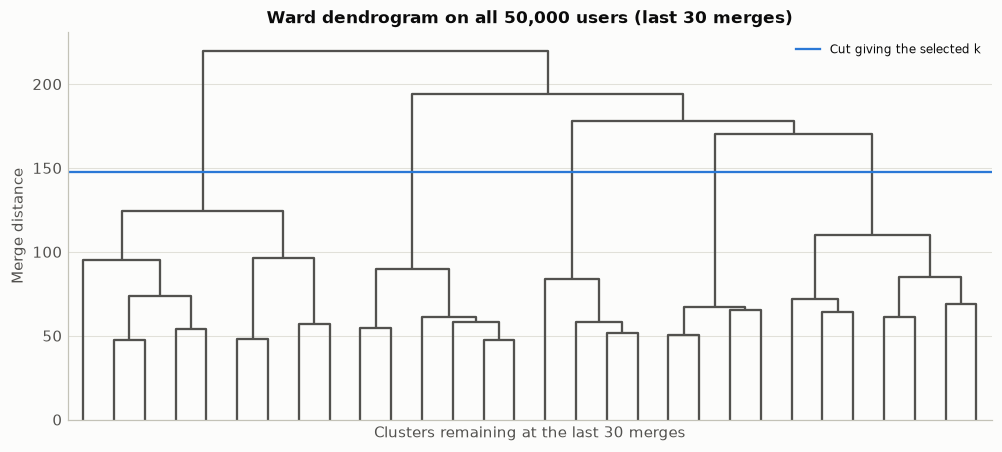

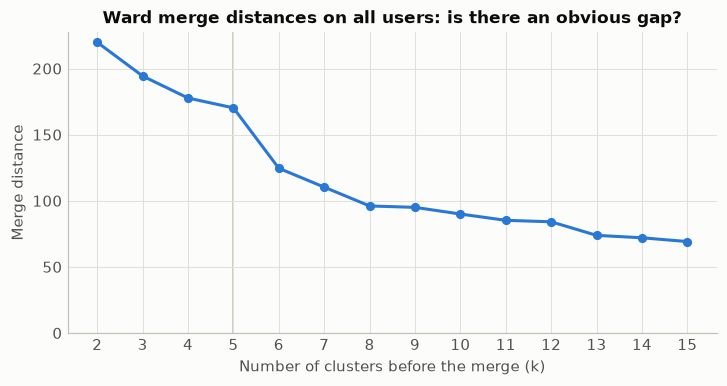

In [7]:
start = time.perf_counter()
full_linkage = full_ward_linkage(X)
ward_fit_seconds = time.perf_counter() - start
print(f"Ward linkage on {len(X):,} users: {ward_fit_seconds:.1f} seconds")

fig = plot_single_dendrogram(full_linkage, f"Ward dendrogram on all {len(X):,} users (last 30 merges)", cut_height(full_linkage, SELECTED_K))
save_figure(fig, "cah_ward_dendrogram_full", config)

fig = plot_merge_heights(full_linkage, SELECTED_K, "Ward merge distances on all users: is there an obvious gap?")
save_figure(fig, "cah_ward_merge_heights", config)

merge_heights = pd.DataFrame({"k_before_merge": range(2, 12), "merge_distance": full_linkage[-1:-11:-1, 2].round(1)})
merge_heights.T

### Does the same gap appear in data with no structure?

A visible gap in a dendrogram is often read as evidence of natural clusters. We can test that reading: fit Ward on three permuted datasets and compute the same quantity, the merge distance from k to k-1 divided by the merge distance from k+1 to k. A large ratio at k means there is a relatively big jump in cost just after reaching k clusters.

In [8]:
def merge_jump_ratios(linkage_matrix, k_values):
    return {k: linkage_matrix[-(k - 1), 2] / linkage_matrix[-k, 2] for k in k_values}

gap_k_values = list(range(2, 11))
merge_jumps = pd.DataFrame(
    {"Real data": merge_jump_ratios(full_linkage, gap_k_values)}
    | {f"Permuted {i + 1}": merge_jump_ratios(full_ward_linkage(permute_columns(X, SEED + i)), gap_k_values) for i in range(3)}
).rename_axis("k")
merge_jumps.to_csv(METRICS_DIR / "cah_merge_jump_ratios.csv")
merge_jumps.round(2)

,Real data,Permuted 1,Permuted 2,Permuted 3
k,,,,
2,1.13,1.06,1.05,1.09
3,1.09,1.13,1.17,1.04
4,1.04,1.10,1.14,1.05
5,1.37,1.27,1.13,1.47
6,1.13,1.06,1.18,1.08
7,1.15,1.07,1.12,1.01
8,1.01,1.04,1.06,1.10
9,1.06,1.23,1.02,1.11
10,1.06,1.01,1.16,1.15


**Reading the dendrogram.** The largest relative jump occurs just after `k = 5`: merging from 6 to 5 clusters costs a distance of 124.6, while merging from 5 to 4 costs 170.3 (ratio 1.37). A traditional reading would call this a natural cut.

**The permuted data shows why that reading fails.** The same jump occurs on data with no joint structure (ratios 1.27, 1.13 and 1.47 at `k = 5`), and one of those is larger than the real value. So the gap comes from how Ward merges a cloud with these feature shapes, and it **cannot be taken as evidence of natural clusters**. It is a helpful pointer for choosing a cut, not proof.

## F. Choosing the number of clusters

The dendrogram alone is not enough, so we combine it with internal metrics and profiles, on the same users and the same Silhouette subset as K-Means. We also repeat the reference test from Notebook 03: Ward is re-fitted on 10 permuted datasets.

,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_share,largest_cluster_share
0,2,0.1328,2.2143,6873.2317,0.2721,0.7279
1,3,0.1104,2.0637,6858.4764,0.1625,0.5654
2,4,0.0995,1.8422,6948.3393,0.1450,0.4205
3,5,0.1037,1.6308,7238.2479,0.1328,0.2876
4,6,0.1013,1.7525,6821.2352,0.1105,0.2876
5,7,0.0952,1.8200,6440.3530,0.0781,0.2095
6,8,0.0827,1.6944,6060.4539,0.0486,0.2095
7,9,0.0813,1.6699,5805.8332,0.0486,0.2095
8,10,0.0723,1.6681,5595.9990,0.0486,0.2095


real                              reference_mean                           percent_difference_from_reference                          
metric calinski_harabasz davies_bouldin silhouette calinski_harabasz davies_bouldin silhouette                 calinski_harabasz davies_bouldin silhouette
k                                                                                                                                                         
2               6873.232          2.214      0.133          7526.672          2.129      0.147                            -8.682          4.010     -9.796
3               6858.476          2.064      0.110          7400.508          2.030      0.118                            -7.324          1.639     -6.628
4               6948.339          1.842      0.099          7444.793          1.787      0.113                            -6.668          3.075    -12.256
5               7238.248          1.631      0.104          7355.543          1.669      0.110                            -1.595         -2.285     -5.623
6               6821.235          1.753      0.101          6975.510          1.666      0.103                            -2.212          5.192     -1.785
7               6440.353          1.820      0.095          6623.260          1.698      0.099                            -2.762          7.204     -3.639
8               6060.454          1.694      0.083          6346.187          1.711      0.093                            -4.502         -0.953    -11.356
9               5805.833          1.670      0.081          6112.154          1.693      0.092                            -5.012         -1.368    -11.240
10              5595.999          1.668      0.072          5898.829          1.678      0.089                            -5.134         -0.588    -18.894

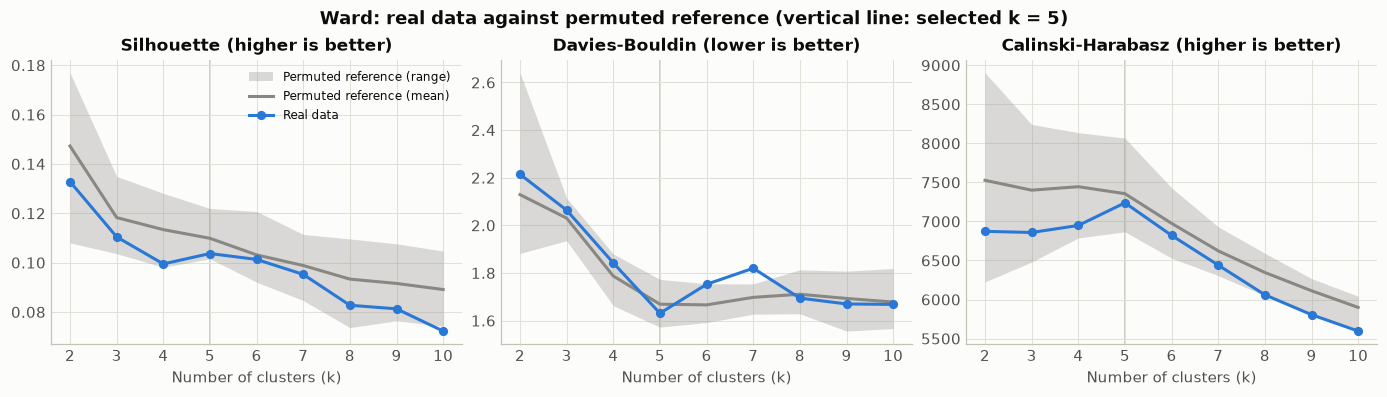

In [9]:
ward_scan = scan_hierarchy(X, full_linkage, K_VALUES, silhouette_index)
ward_scan.to_csv(METRICS_DIR / "cah_ward_k_scan.csv", index=False)

ward_reference = reference_scan(X, K_VALUES, "ward", EVALUATION["reference_datasets"], SEED, silhouette_index)
ward_reference.to_csv(METRICS_DIR / "cah_ward_reference_scan.csv", index=False)
ward_reference_summary = summarise_reference(ward_reference)

fig = plot_metrics_vs_reference(ward_scan, ward_reference_summary, SELECTED_K, "Ward: real data against permuted reference")
save_figure(fig, "cah_metrics_vs_reference", config)

ward_vs_reference = compare_to_reference(ward_scan, ward_reference_summary)
ward_vs_reference.to_csv(METRICS_DIR / "cah_ward_vs_reference.csv", index=False)
display(ward_scan.round(4))
ward_vs_reference.pivot(index="k", columns="metric", values=["real", "reference_mean", "percent_difference_from_reference"]).round(3)

In [10]:
for k in [2, 4, 5, 6]:
    labels = cut_tree(full_linkage, k)
    profile = users.groupby(labels)[NUMERIC_FEATURES].mean().round(2)
    profile["percent_of_users"] = (100 * np.bincount(labels) / len(labels)).round(1)
    print(f"k = {k}")
    display(profile)

k = 2


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,percent_of_users
0,11.17,8.21,13.41,3.91,27.2
1,9.55,7.92,8.76,3.54,72.8


k = 4


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,percent_of_users
0,11.17,8.21,13.41,3.91,27.2
1,8.15,7.89,9.20,2.11,16.2
2,6.39,5.71,9.92,4.16,14.5
3,11.18,8.70,8.19,3.89,42.0


k = 5


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,percent_of_users
0,11.17,8.21,13.41,3.91,27.2
1,8.15,7.89,9.20,2.11,16.2
2,6.39,5.71,9.92,4.16,14.5
3,8.41,11.29,9.07,4.23,13.3
4,12.46,7.51,7.79,3.73,28.8


k = 6


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,percent_of_users
0,9.35,7.63,14.39,3.68,16.2
1,13.82,9.05,11.97,4.25,11.0
2,8.15,7.89,9.20,2.11,16.2
3,6.39,5.71,9.92,4.16,14.5
4,8.41,11.29,9.07,4.23,13.3
5,12.46,7.51,7.79,3.73,28.8


### Stability

Ward has no random starting point, so re-running on the same data gives the same tree. What can vary is the answer when the *data* changes. As in Notebook 03, we fit on 10 independent subsamples and compare partitions on a shared set of users, using the nearest-cluster-mean rule purely as a means of comparison.

dataset,Permuted reference,Real data
k,,
2,0.357,0.272
3,0.283,0.286
4,0.337,0.297
5,0.368,0.350
6,0.342,0.322
7,0.320,0.305
8,0.308,0.304
9,0.299,0.294
10,0.296,0.290


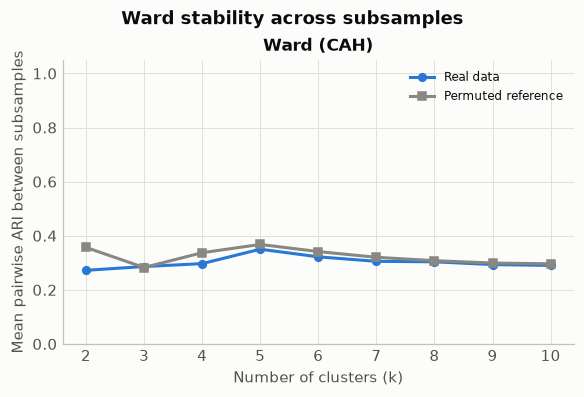

In [11]:
def ward_labels(X_subset, k, run):
    return cut_tree(sample_linkage(X_subset, "ward"), k)

ward_stability = stability_table(
    X, ward_labels, "Ward (CAH)", K_VALUES, EVALUATION["stability_subsamples"], EVALUATION["stability_subsample_size"], SEED
)
ward_stability.to_csv(METRICS_DIR / "cah_subsample_stability.csv", index=False)
fig = plot_stability(ward_stability, "Ward stability across subsamples")
save_figure(fig, "cah_stability", config)
ward_stability.pivot(index="k", columns="dataset", values="mean_ari").round(3)

### Selecting `k`

| Evidence | Finding on all 50,000 users |
|---|---|
| Dendrogram | Largest relative merge jump after `k = 5`, also seen in permuted data |
| Silhouette | Best at `k = 2` (0.133), then `k = 3` (0.110); `k = 5` is a local peak (0.104) |
| Davies-Bouldin | **Best of all at `k = 5`** (1.631) |
| Calinski-Harabasz | **Best of all at `k = 5`** (7,238) |
| Subsample stability | **Best at `k = 5`** on real data, but only 0.350 |
| Interpretability | `k = 2` only separates frequent skippers from the rest; `k = 5` gives distinct profiles on all four features |

**Decision: `k = 5`.** This was chosen on its own evidence, not to match K-Means, and the same value being selected does make the comparison direct. **Alternative:** `k = 2` has the best Silhouette, but it collapses the data into only two groups.

**The same caveat applies, more strongly:** at `k = 5`, all three real values lie inside the permuted reference range (Silhouette 0.102 to 0.122, Davies-Bouldin 1.573 to 1.773, Calinski-Harabasz 6,867 to 8,067). Stability is just as low on permuted data (0.368).

## G. Final CAH solution

,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5
Frequent Skippers,0.30,0.07,1.07,0.24
Low-Rating Users,-0.46,-0.04,-0.26,-1.38
Light Listeners,-0.91,-0.81,-0.03,0.46
Playlist Builders,-0.40,1.16,-0.30,0.53
Low-Skip Listeners,0.62,-0.18,-0.71,0.08


,users,percent
segment,,
Low-Skip Listeners,14382,28.76
Frequent Skippers,13603,27.21
Low-Rating Users,8125,16.25
Light Listeners,7248,14.50
Playlist Builders,6642,13.28


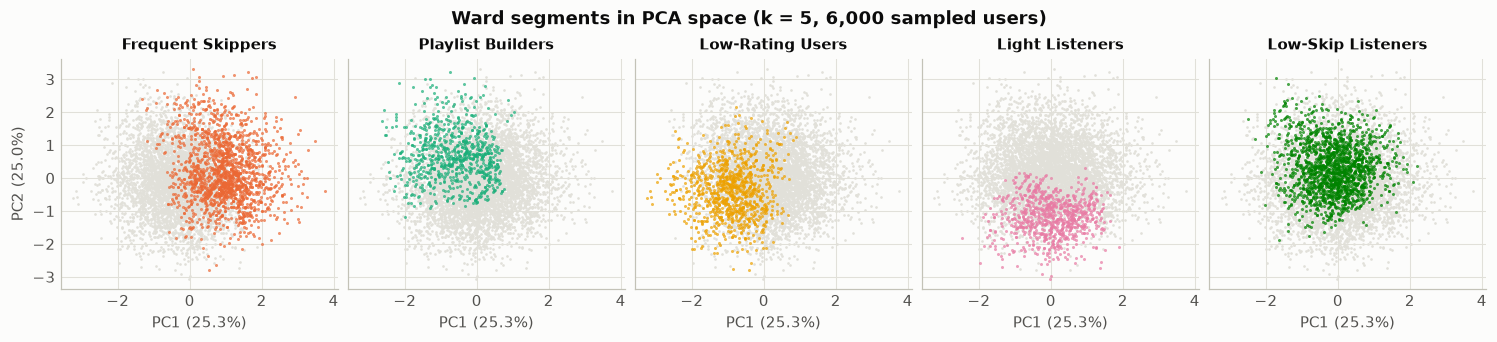

In [12]:
ward_final_labels = cut_tree(full_linkage, SELECTED_K)

ward_z_profile = pd.DataFrame(X, columns=NUMERIC_FEATURES).groupby(ward_final_labels).mean()
ward_names = name_segments(ward_z_profile)
ward_segments = pd.Series(ward_final_labels).map(ward_names).rename("ward_segment")

ward_sizes = size_table(ward_segments)
ward_sizes.to_csv(PROFILES_DIR / "cah_cluster_sizes.csv")
display(ward_z_profile.rename(index=ward_names).round(2))
display(ward_sizes)

pca = PCA(random_state=SEED).fit(X)
coordinates = pca.transform(X)[:, :2]
fig = plot_pca_segments(coordinates, ward_segments, pca.explained_variance_ratio_, f"Ward segments in PCA space (k = {SELECTED_K}, 6,000 sampled users)", SEED)
save_figure(fig, "cah_pca_segments", config)

### Would a sample have been enough?

Fitting on all users makes sampling unnecessary here, but it is worth knowing how far a sample-based model would have gone wrong. We take the Ward tree from the 5,000-user sample, cut it at the same `k`, assign all users to the nearest cluster mean, and compare with the full-data solution.

In [13]:
sample_ward_labels = cut_tree(sample_linkages["ward"], SELECTED_K)
extended_labels = assign_to_nearest_centroid(X_sample, sample_ward_labels, X)
sample_vs_full_ari = adjusted_rand_score(ward_final_labels, extended_labels)
print(f"ARI between the extended sample solution and the full-data solution: {sample_vs_full_ari:.3f}")

ARI between the extended sample solution and the full-data solution: 0.334


**Result: ARI of only 0.334.** A sample-based solution would have labelled users quite differently from the full-data solution. This matches the low subsample stability above, and it confirms that fitting on all users was worthwhile. It also means **the sampled dendrograms in Section D illustrate the method but should not be read as a picture of the full data.**

## H. Representation B with Ward

As with K-Means, values from a different feature space are not directly comparable with Representation A. We use the same vector-based Ward fit.

In [14]:
mixed_linkage = full_ward_linkage(X_mixed)
mixed_ward_scan = scan_hierarchy(X_mixed, mixed_linkage, K_VALUES, silhouette_index)
mixed_ward_scan.to_csv(METRICS_DIR / "cah_ward_representation_b_scan.csv", index=False)
display(mixed_ward_scan.round(3))

mixed_ward_labels = cut_tree(mixed_linkage, SELECTED_K)
print(f"ARI with the Representation A Ward partition at k = {SELECTED_K}: {adjusted_rand_score(ward_final_labels, mixed_ward_labels):.3f}")
for column in config["columns"]["representation_b_categorical"]:
    shares = 100 * pd.crosstab(mixed_ward_labels, users[column], normalize="index")
    print(f"{column}: largest difference in any category's share between clusters = {(shares.max() - shares.min()).max():.1f} percentage points")

,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_share,largest_cluster_share
0,2,0.096,2.784,4619.042,0.255,0.745
1,3,0.051,3.136,3750.522,0.238,0.507
2,4,0.041,2.940,3388.382,0.215,0.292
3,5,0.033,2.660,3091.350,0.065,0.292
4,6,0.024,2.960,2745.252,0.065,0.292
5,7,0.014,3.200,2477.875,0.065,0.238
6,8,0.008,3.325,2292.254,0.065,0.178
7,9,0.006,3.175,2141.124,0.055,0.178
8,10,0.007,3.041,2022.660,0.055,0.150


ARI with the Representation A Ward partition at k = 5: 0.119
favorite_genre: largest difference in any category's share between clusters = 8.3 percentage points
primary_device: largest difference in any category's share between clusters = 32.8 percentage points


**Result: Ward reacts very differently from K-Means to one-hot columns.** The partition changes almost completely (ARI 0.119). Clusters now differ by up to 32.8 percentage points in device share and 8.3 in genre share, while Silhouette falls to 0.033 at `k = 5`. Ward's merges are pulled by exact matches on the 0/1 columns, so the partition follows category membership rather than listening behaviour. **Representation A is kept as the final basis.** This confirms that adding columns is not automatically an improvement.

## I. Save the results

In [15]:
ward_label_table = pd.DataFrame(
    {"user_id": users["user_id"], "ward_label": ward_final_labels, "ward_segment": ward_segments}
)
ward_label_table.to_csv(PROFILES_DIR / "cah_labels.csv", index=False)

ward_record = {
    "algorithm": "Agglomerative hierarchical clustering",
    "implementation_full_data": "fastcluster.linkage_vector",
    "representation": "A",
    "features": NUMERIC_FEATURES,
    "linkage": cah_settings["final_linkage"],
    "metric": cah_settings["metric"],
    "selected_k": SELECTED_K,
    "fitted_on_all_users": True,
    "fit_seconds": ward_fit_seconds,
    "linkage_comparison_sample": {
        "size": cah_settings["sample_size"],
        "method": "Uniform random sample without replacement",
        "random_seed": SEED,
    },
    "implementation_agreement_ari": implementation_agreement,
    "extended_sample_vs_full_ari": sample_vs_full_ari,
    "segment_names": {str(label): name for label, name in ward_names.items()},
}
with open(METRICS_DIR / "cah_model_config.json", "w", encoding="utf-8") as file:
    json.dump(ward_record, file, indent=2)

assert len(ward_label_table) == len(users) and ward_label_table["user_id"].is_unique
print("Saved Ward labels, sizes, metrics and configuration.")

Saved Ward labels, sizes, metrics and configuration.


## Conclusion

- **Selected model:** Ward linkage with Euclidean distance and `k = 5`, fitted on all 50,000 users using `fastcluster`.
- **Segments:** Low-Skip Listeners (28.76%), Frequent Skippers (27.21%), Low-Rating Users (16.25%), Light Listeners (14.50%) and Playlist Builders (13.28%).
- **Quality:** Silhouette 0.104 on the fixed subset, which is weak.
- **Stability:** low (ARI 0.350 across subsamples), and a sample-based model would not reproduce the full-data solution (ARI 0.334).
- **Main caveat:** as with K-Means, scores match data with no joint structure, and the dendrogram gap appears in permuted data too.